# Maxwell-Garnett Inversion for water-oil suspensions

This notebook is an implementation for the effective medium model for water-oil suspensions, which can be approximated as a composite media at THz frequencies.

###Maxwell-Garnett Effective Medium Model

Since the droplets are spherical and the suspensions are dilute, Maxwell-Garnett theory can be used to give the effective complex permittivity of spherical inclusions in a host medium as shown by the equation below.

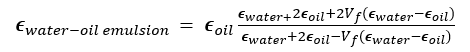


###a. Linearised Maxwell-Garnett model
A linearised Maxwell-Garnett model, as derived by Sihvola, which neglects droplet interaction and scattering for highly dilute systems is tested as well.

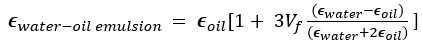


###3. Bruggemann Effective Medium Model
The Bruggemann model is tested as well, which approximates the water-oil suspension as a self-consistent mixing approach that symmetrically incorporates both matrix and inclusion phases.

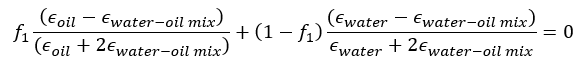

####References
1. Garnett, J. M. (1906). Colours in metal glasses, in metallic films, and in metallic solutions. II. Philosophical Transactions of the Royal Society of London. Series A, Containing Papers of a Mathematical or Physical Character, 237-288.
2. Markel, V. A. (2016). Maxwell Garnett approximation (advanced topics): tutorial. Journal of the Optical Society of America A, 33(11), 2237-2255.
3.  Bruggeman, D.A.G. (1935), Berechnung verschiedener physikalischer Konstanten von heterogenen Substanzen. I. Dielektrizitätskonstanten und Leitfähigkeiten der Mischkörper aus isotropen Substanzen. Ann. Phys., 416: 636-664.
4. Sihvola, A. (2007). Metamaterials in electromagnetics. Metamaterials, 1(1), 2-11.
5. Sihvola, A. (2007). Dielectric polarization and particle shape effects. Journal of Nanomaterials, 2007(1), 45090.

#### Import dataset

In this case, both complex refractive index and complex permittivity are imported, then columns and first few rows are inspected.

1. Pure oil
2. Water-oil Mix

In [12]:
import pandas as pd

file_path = '/content/Water-Oil Mix.xlsx'
xl = pd.ExcelFile(file_path)

print("Sheet names found in the Excel file:", xl.sheet_names)

for sheet in xl.sheet_names:
    df_temp = pd.read_excel(file_path, sheet_name=sheet, nrows=5)
    print(f"\nColumns in sheet '{sheet}':")
    print(df_temp.columns.tolist())
    display(df_temp.head(3))

Sheet names found in the Excel file: ['Paraffin', '1%Vf']

Columns in sheet 'Paraffin':
['Frequency/ THz', 'Refractive Index', 'Extinction Coefficient', 'Real Permittivity', 'Imaginary Permittivity']


,Frequency/ THz,Refractive Index,Extinction Coefficient,Real Permittivity,Imaginary Permittivity
0,0.00,--,--,--,--
1,0.02,1.48995,0.04296,2.21811,0.12803
2,0.04,1.32247,-0.10282,1.73834,-0.27196



Columns in sheet '1%Vf':
['Frequency/ THz', 'Refractive Index', 'Extinction Coefficient', 'Real Permittivity', 'Imaginary Permittivity']


,Frequency/ THz,Refractive Index,Extinction Coefficient,Real Permittivity,Imaginary Permittivity
0,0.00,--,--,--,--
1,0.02,1.58129,-0.03824,2.499,-0.12093
2,0.04,1.52829,--,--,--


#### Define a function invert_maxwell_garnett with the following parameters -

1. eps_mix : complex permittivity of the water-oil mix

2. eps_host: complex permittivity of pure oil

3. f : volume fraciton the inclusion ( 0 <= f <= 1)

The Maxwell Garnett equation (defined above) is inverted to find the complex permittivity of the inclusion, i.e water


In [10]:
import numpy as np
import pandas as pd

def invert_maxwell_garnett(eps_mix, eps_host, f):
    """
    Inverts the Maxwell Garnett formula to solve for the complex permittivity of the inclusion (water).

    Returns:
    complex: Complex permittivity of the inclusion (water).
    """

    # Maxwell Garnett Inversion formula
    numerator = 2 * eps_mix + eps_host + 2 * f * (eps_mix - eps_host)
    denominator = 2 * eps_mix + eps_host - f * (eps_mix - eps_host)
    eps_inclusion = eps_host * (numerator / denominator)
    return eps_inclusion

# Define volume fraction
f = 0.01

# Construct complex permittivity for host (oil) and mixture
# We will use the non-negative cleaned datasets
df_oil_clean = df_oil.dropna()
df_mix_clean = df_mix.dropna()

# Aligned merge on frequency
df_merged = pd.merge(df_oil_clean, df_mix_clean, on='Frequency/ THz', suffixes=('_oil', '_mix'))

# Reconstruct complex numbers
eps_host = df_merged['Real Permittivity_oil'] + 1j * df_merged['Imaginary Permittivity_oil']
eps_mix = df_merged['Real Permittivity_mix'] + 1j * df_merged['Imaginary Permittivity_mix']

# Run inversion
eps_water = invert_maxwell_garnett(eps_mix, eps_host, f)

# Output results into a preview DataFrame
results = pd.DataFrame({
    'Frequency (THz)': df_merged['Frequency/ THz'],
    'Water Real Permittivity': np.real(eps_water),
    'Water Imaginary Permittivity': np.imag(eps_water)
})

display(results.head(10))

,Frequency (THz),Water Real Permittivity,Water Imaginary Permittivity
0,0.0200,2.220866,0.125925
1,0.0799,2.153964,0.071636
2,0.0999,2.169850,0.006228
3,0.1199,2.182166,0.012041
4,0.1399,2.175128,0.019522
5,0.1598,2.168855,-0.000011
6,0.1798,2.173246,-0.000712
7,0.1998,2.175661,0.013984
8,0.2198,2.169852,0.011153
9,0.2398,2.172000,-0.000276


#### Define a function invert_bruggemann with the following parameters -

1. eps_mix : complex permittivity of the water-oil mix

2. eps_host: complex permittivity of pure oil

3. f : volume fraciton the inclusion ( 0 <= f <= 1)

The Bruggemann equation is inverted to find the complex permittivity of the inclusion, i.e water.

In [13]:
def invert_bruggeman(eps_mix, eps_host, f):
    """
    Inverts the Bruggeman formula to find the complex permittivity of the inclusion (water).

    Letting C = (1-f) * (eps_host - eps_mix)/(eps_host + 2*eps_mix):
    f * (eps_inc - eps_mix) + C * (eps_inc + 2*eps_mix) = 0
    eps_inc * (f + C) = f*eps_mix - 2*C*eps_mix
    eps_inc = eps_mix * (f - 2*C) / (f + C)
    """
    # Calculate constant component from the host phase contribution
    C = (1 - f) * (eps_host - eps_mix) / (eps_host + 2 * eps_mix)

    # Solve for inclusion complex permittivity
    eps_inclusion = eps_mix * (f - 2 * C) / (f + C)
    return eps_inclusion

# Run the Bruggeman inversion with the same 1% volume fraction
eps_water_bruggeman = invert_bruggeman(eps_mix, eps_host, f)

# Put results in a DataFrame
results_bruggeman = pd.DataFrame({
    'Frequency (THz)': df_merged['Frequency/ THz'],
    'Water Real Permittivity (Bruggeman)': np.real(eps_water_bruggeman),
    'Water Imaginary Permittivity (Bruggeman)': np.imag(eps_water_bruggeman)
})

display(results_bruggeman.head(10))

,Frequency (THz),Water Real Permittivity (Bruggeman),Water Imaginary Permittivity (Bruggeman)
0,0.0200,-6.166059,-0.981184
1,0.0799,-8.503543,-0.520671
2,0.0999,-12.152375,6.257846
3,0.1199,42.321867,-0.617665
4,0.1399,11.707229,23.281347
5,0.1598,2.649517,11.982305
6,0.1798,2.109787,10.416003
7,0.1998,4.264923,6.132629
8,0.2198,6.885156,6.320552
9,0.2398,1.684791,6.643818


In [22]:
def invert_sihvola_linearized_mg(eps_mix, eps_host, f):
    """
    Inverts Sihvola's linearized Maxwell Garnett equation for a dilute mixture (f << 1).

    Formula:
    eps_inc = eps_host * (3 * f * eps_host + 2 * (eps_mix - eps_host)) / (3 * f * eps_host - (eps_mix - eps_host))
    """
    delta = eps_mix - eps_host
    numerator = 3 * f * eps_host + 2 * delta
    denominator = 3 * f * eps_host - delta
    eps_inclusion = eps_host * (numerator / denominator)
    return eps_inclusion

# Calculate complex permittivity of water using Sihvola's linearized model
eps_water_sihvola = invert_sihvola_linearized_mg(eps_mix, eps_host, f)

# Put results into a DataFrame
results_sihvola = pd.DataFrame({
    'Frequency (THz)': df_merged['Frequency/ THz'],
    'Water Real Permittivity (Sihvola)': np.real(eps_water_sihvola),
    'Water Imaginary Permittivity (Sihvola)': np.imag(eps_water_sihvola)
})

display(results_sihvola.head(10))

,Frequency (THz),Water Real Permittivity (Sihvola),Water Imaginary Permittivity (Sihvola)
0,0.0200,-5.179708,-1.371410
1,0.0799,-7.443501,-0.478041
2,0.0999,-10.975474,5.470304
3,0.1199,50.328008,-0.965538
4,0.1399,9.372108,24.687088
5,0.1598,2.097452,11.823286
6,0.1798,1.721660,10.247584
7,0.1998,4.136510,6.172549
8,0.2198,6.778984,6.499658
9,0.2398,1.563751,6.550915


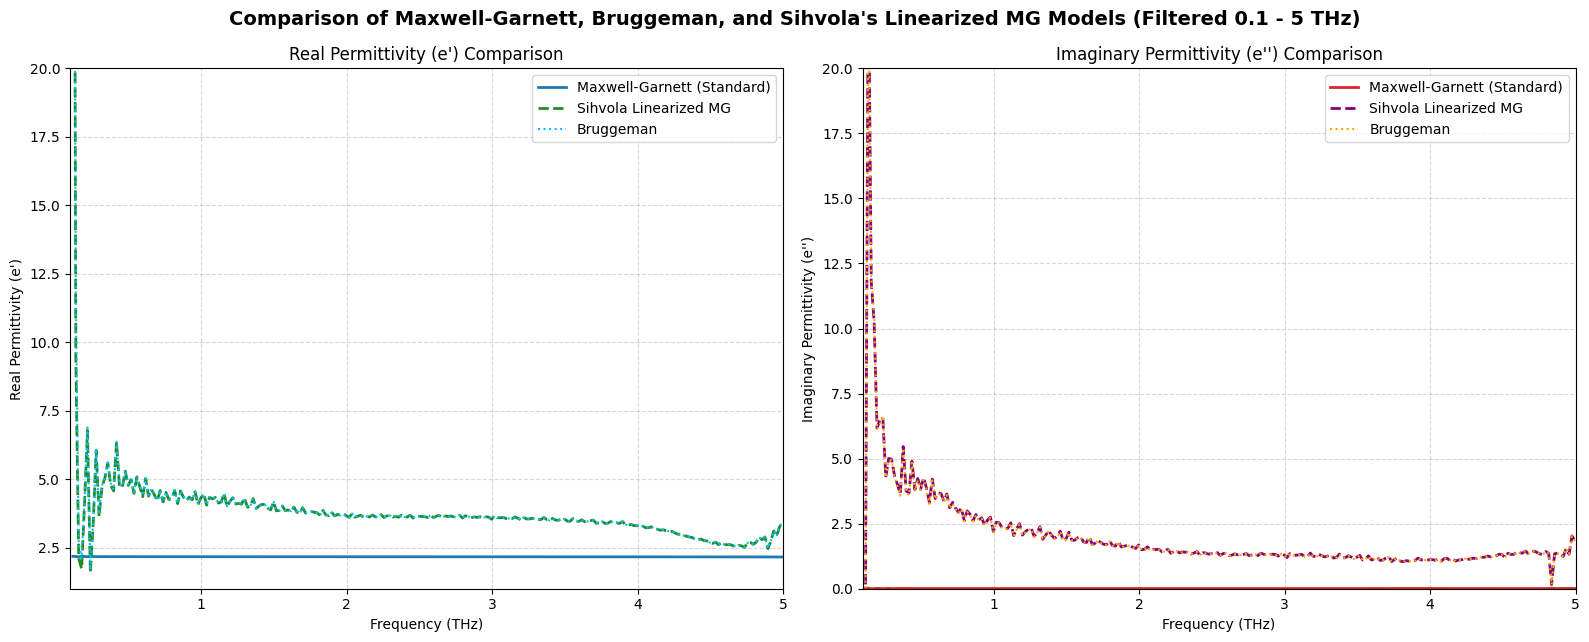

In [26]:
import matplotlib.pyplot as plt

# Filter the data between 0.1 THz and 5.0 THz
mask = (results['Frequency (THz)'] >= 0.1) & (results['Frequency (THz)'] <= 5.0)

f_filtered = results.loc[mask, 'Frequency (THz)']
real_mg = results.loc[mask, 'Water Real Permittivity']
imag_mg = results.loc[mask, 'Water Imaginary Permittivity']

real_sihvola = results_sihvola.loc[mask, 'Water Real Permittivity (Sihvola)']
imag_sihvola = results_sihvola.loc[mask, 'Water Imaginary Permittivity (Sihvola)']

real_bruggeman = results_bruggeman.loc[mask, 'Water Real Permittivity (Bruggeman)']
imag_bruggeman = results_bruggeman.loc[mask, 'Water Imaginary Permittivity (Bruggeman)']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

# Subplot 1: Real Permittivity Comparison
ax1.plot(f_filtered, real_mg, color='tab:blue', label='Maxwell-Garnett (Standard)', linewidth=2)
ax1.plot(f_filtered, real_sihvola, color='forestgreen', linestyle='--', label='Sihvola Linearized MG', linewidth=2)
ax1.plot(f_filtered, real_bruggeman, color='deepskyblue', linestyle=':', label='Bruggeman', linewidth=1.5)
ax1.set_xlabel('Frequency (THz)')
ax1.set_ylabel("Real Permittivity (e')")
ax1.set_title("Real Permittivity (e') Comparison")
ax1.set_xlim(0.1, 5.0)
ax1.set_ylim(1.0, 10.0)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Subplot 2: Imaginary Permittivity Comparison
ax2.plot(f_filtered, imag_mg, color='tab:red', linestyle='-', label='Maxwell-Garnett (Standard)', linewidth=2)
ax2.plot(f_filtered, imag_sihvola, color='purple', linestyle='--', label='Sihvola Linearized MG', linewidth=2)
ax2.plot(f_filtered, imag_bruggeman, color='orange', linestyle=':', label='Bruggeman', linewidth=1.5)
ax2.set_xlabel('Frequency (THz)')
ax2.set_ylabel("Imaginary Permittivity (e'')")
ax2.set_title("Imaginary Permittivity (e'') Comparison")
ax2.set_xlim(0.1, 5.0)
ax2.set_ylim(0.0, 20.0)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.suptitle("Comparison of Maxwell-Garnett, Bruggeman, and Sihvola's Linearized MG Models (Filtered 0.1 - 5 THz)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()